# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

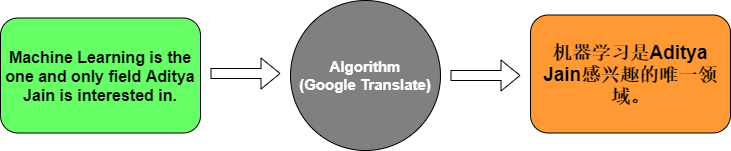

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
%pip install -q tensorflow pandas scikit-learn matplotlib kagglehub sacrebleu

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

tf.keras.utils.set_random_seed(42)

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 18s 18s/step - accuracy: 0.0000e+00 - loss: 2.4878 - val_accuracy: 0.0000e+00 - val_loss: 2.4883
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5714 - loss: 2.4792 - val_accuracy: 0.0000e+00 - val_loss: 2.4900
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5714 - loss: 2.4706 - val_accuracy: 0.0000e+00 - val_loss: 2.4919
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.4615 - val_accuracy: 0.0000e+00 - val_loss: 2.4940
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5714 - loss: 2.4517 - val_accuracy: 0.0000e+00 - val_loss: 2.4962
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5714 - loss: 2.4407 - val_accuracy: 0.0000e+00 - val_loss: 2.4988
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5714 - loss: 2.4281 - val_accuracy: 0.0000e+00 - val_loss: 2.5016
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4137 - val_acc

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sequence = [[int(i) for i in row if i != 0] for row in translated_sequence]
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

**About the three-sentence example:** This demonstrates the architecture only. After splitting, the training/validation subsets are extremely small, so its test accuracy and translation are not reliable measures of translation quality.

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. **Embedding:** Converts each integer word ID into a trainable dense vector. The vector is a numerical representation that the model updates while learning.
2. **Encoder LSTM:** Reads the English word vectors in order and compresses the sentence information into its final hidden output (the context vector).
3. **Decoder LSTM:** Receives the repeated context vector and produces an output at every French sentence position. The final Dense layer converts each output into word scores/probabilities.
4. **Softmax:** Converts the final scores into probabilities over the French vocabulary. The probabilities sum to 1 at each position, so we can select the most probable word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 — English–French translation
**Pipeline:** load → clean → split → training-only tokenizers → shifted French inputs/targets → encoder–decoder → training → held-out evaluation → autoregressive translation.

Example of teacher forcing:
- Decoder input: `startseq bonjour`
- Expected output: `bonjour endseq`

PAD (`0`) is excluded from loss and accuracy. Both encoder states (hidden and cell) initialize the decoder. The inference models reuse the trained layers.

In [8]:
from pathlib import Path
import re
import unicodedata
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
MAX_PAIRS = 30000       # Random subset after cleaning; None uses all eligible pairs.
MAX_WORDS = 12          # Use short sentences for this introductory baseline.
VOCAB_LIMIT = 10000
EMBED_DIM = 128
LATENT_DIM = 256
EPOCHS = 30
BATCH_SIZE = 64
CSV_PATH = ""          # e.g. "/content/eng_-french.csv" to skip download.

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

if CSV_PATH:
    csv_path = Path(CSV_PATH)
else:
    import kagglehub
    try:
        dataset_dir = Path(kagglehub.dataset_download(
            "devicharith/language-translation-englishfrench"))
    except Exception as exc:
        raise RuntimeError("Download failed. Download the assigned Kaggle CSV, "
                           "upload it to Colab, set CSV_PATH, and rerun Task 2.") from exc
    csv_files = sorted(dataset_dir.rglob("*.csv"))
    if len(csv_files) != 1:
        raise ValueError("Set CSV_PATH to the intended English–French CSV.")
    csv_path = csv_files[0]
raw = pd.read_csv(csv_path)
print("File:", csv_path.name, "| Original rows:", len(raw))
print("Columns:", raw.columns.tolist())
display(raw.head())

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
File: eng_-french.csv | Original rows: 175621
Columns: ['English words/sentences', 'French words/sentences']


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [9]:
def normalize_text(text):
    text = unicodedata.normalize("NFKC", str(text)).lower().replace("’", "'")
    # Preserve accents and apostrophes; remove punctuation consistently.
    text = re.sub(r"[^\w\s']", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()

lookup = {str(c).strip().lower(): c for c in raw.columns}
eng_col = next((lookup[k] for k in ["english words/sentences", "english", "en"]
                if k in lookup), None)
fr_col = next((lookup[k] for k in ["french words/sentences", "french", "fr"]
               if k in lookup), None)
if eng_col is None or fr_col is None:
    raise ValueError("Set eng_col and fr_col to the English and French column names.")

data = raw[[eng_col, fr_col]].dropna().copy()
data.columns = ["english", "french"]
for col in data.columns:
    data[col] = data[col].map(normalize_text)
data = data[(data.english != "") & (data.french != "")]
# One translation per normalized English input prevents identical source leakage.
data = data.drop_duplicates(subset="english")
length_ok = (data.english.str.split().str.len().between(1, MAX_WORDS)
             & data.french.str.split().str.len().between(1, MAX_WORDS))
data = data[length_ok]
if MAX_PAIRS is not None and len(data) > MAX_PAIRS:
    data = data.sample(n=MAX_PAIRS, random_state=SEED)
data = data.reset_index(drop=True)
if len(data) < 30:
    raise ValueError("Too few usable parallel sentences.")

train_df, other_df = train_test_split(data, test_size=0.2, random_state=SEED)
val_df, test_df = train_test_split(other_df, test_size=0.5, random_state=SEED)
assert not set(train_df.english) & set(test_df.english)
assert not set(train_df.english) & set(val_df.english)
assert not set(val_df.english) & set(test_df.english)
print(f"Train={len(train_df)}, validation={len(val_df)}, test={len(test_df)}")
display(train_df.head())

Train=24000, validation=3000, test=3000


,english,french
21753,you can see the ancient ruins in the distance,vous pouvez voir les anciennes ruines au loin
251,dreams sometimes come true,quelquefois les rêves deviennent réalité
22941,you should've started without me,tu aurais dû commencer sans moi
618,i'm looking for an easy to read manga with fur...,je cherche un manga facile à lire et avec des ...
17090,i hate milk,je déteste le lait


In [10]:
# No filters: normalization has already been applied consistently.
source_tokenizer = Tokenizer(num_words=VOCAB_LIMIT, oov_token="<unk>", filters="")
target_tokenizer = Tokenizer(num_words=VOCAB_LIMIT, oov_token="<unk>", filters="")
source_tokenizer.fit_on_texts(train_df.english.tolist())
target_tokenizer.fit_on_texts(
    ["startseq " + s + " endseq" for s in train_df.french])
source_vocab = min(VOCAB_LIMIT, len(source_tokenizer.word_index) + 1)
target_vocab = min(VOCAB_LIMIT, len(target_tokenizer.word_index) + 1)
START_ID = target_tokenizer.word_index["startseq"]
END_ID = target_tokenizer.word_index["endseq"]
UNK_ID = target_tokenizer.word_index["<unk>"]
assert max(START_ID, END_ID) < target_vocab
SOURCE_LEN = MAX_WORDS
TARGET_LEN = MAX_WORDS + 1  # All French words plus endseq, or startseq plus words.

def encode_pairs(frame):
    source = source_tokenizer.texts_to_sequences(frame.english.tolist())
    target = target_tokenizer.texts_to_sequences(
        ["startseq " + s + " endseq" for s in frame.french])
    x = pad_sequences(source, maxlen=SOURCE_LEN, padding="post", truncating="post")
    # Shift BEFORE padding. startseq is input only; endseq is a supervised target.
    dec_in = pad_sequences([s[:-1] for s in target], maxlen=TARGET_LEN,
                           padding="post", truncating="post")
    dec_out = pad_sequences([s[1:] for s in target], maxlen=TARGET_LEN,
                            padding="post", truncating="post")
    return x, dec_in, dec_out

x_train, din_train, y_train = encode_pairs(train_df)
x_val, din_val, y_val = encode_pairs(val_df)
x_test, din_test, y_test = encode_pairs(test_df)
assert np.all(din_train[:, 0] == START_ID)
assert np.all(np.sum(y_train == END_ID, axis=1) == 1)
for decoder_row, target_row in zip(din_train, y_train):
    n_words = int(np.sum(target_row != 0)) - 1
    assert np.array_equal(decoder_row[1:n_words + 1], target_row[:n_words])
print("Shapes:", x_train.shape, din_train.shape, y_train.shape)
print("Source / target vocabulary:", source_vocab, target_vocab)
print("Decoder input:", target_tokenizer.sequences_to_texts([din_train[0]]))
print("Decoder target:", target_tokenizer.sequences_to_texts([y_train[0]]))
nonpad = y_test != 0
print("Test target unknown-token rate:",
      float(np.sum((y_test == UNK_ID) & nonpad) / np.sum(nonpad)))

Shapes: (24000, 12) (24000, 13) (24000, 13)
Source / target vocabulary: 7152 10000
Decoder input: ['startseq vous pouvez voir les anciennes ruines au loin <unk> <unk> <unk> <unk>']
Decoder target: ['vous pouvez voir les anciennes ruines au loin endseq <unk> <unk> <unk> <unk>']
Test target unknown-token rate: 0.03574144486692015


In [11]:
@tf.keras.utils.register_keras_serializable(package="Lab10")
def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    losses = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(y_true != 0, losses.dtype)
    return tf.math.divide_no_nan(tf.reduce_sum(losses * mask), tf.reduce_sum(mask))

@tf.keras.utils.register_keras_serializable(package="Lab10")
class MaskedTokenAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="token_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.count = self.add_weight(name="count", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(y_true, tf.int64)
        predicted = tf.argmax(y_pred, axis=-1, output_type=tf.int64)
        weights = tf.cast(y_true != 0, self.dtype)
        if sample_weight is not None:
            weights *= tf.cast(sample_weight, self.dtype)
        correct = tf.cast(tf.equal(y_true, predicted), self.dtype)
        self.correct.assign_add(tf.reduce_sum(correct * weights))
        self.count.assign_add(tf.reduce_sum(weights))

    def result(self):
        return tf.math.divide_no_nan(self.correct, self.count)

    def reset_state(self):
        self.correct.assign(0.0)
        self.count.assign(0.0)

# Encoder: integer IDs -> embeddings -> final hidden and cell states.
encoder_input = tf.keras.Input(shape=(None,), dtype="int32", name="english")
source_embedding = tf.keras.layers.Embedding(source_vocab, EMBED_DIM, mask_zero=True)
encoder_lstm = tf.keras.layers.LSTM(LATENT_DIM, return_state=True)
_, state_h, state_c = encoder_lstm(source_embedding(encoder_input))

# Decoder: previous French tokens, initialized with both encoder states.
decoder_input = tf.keras.Input(shape=(None,), dtype="int32", name="french_prefix")
# Right-padded target positions are ignored explicitly by the loss/metric.
# No automatic decoder mask: this avoids applying a second loss normalization.
target_embedding = tf.keras.layers.Embedding(target_vocab, EMBED_DIM)
decoder_lstm = tf.keras.layers.LSTM(LATENT_DIM, return_sequences=True, return_state=True)
decoder_output, _, _ = decoder_lstm(
    target_embedding(decoder_input), initial_state=[state_h, state_c])
word_classifier = tf.keras.layers.Dense(target_vocab, activation="softmax")
probabilities = word_classifier(decoder_output)
translation_model = tf.keras.Model([encoder_input, decoder_input], probabilities)
translation_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss=masked_loss, metrics=[MaskedTokenAccuracy()])
translation_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_prefix       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 128) │    915,456 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 128) │  1,280,000 │ french_prefix[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 256),     │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, None,     │    394,240 │ embedding_2[0][0… │
│                     │ 256), (None,      │            │ lstm_2[0][1],     │
│                     │ 256), (None,      │            │ lstm_2[0][2]      │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │  2,570,000 │ lstm_3[0][0]      │
│                     │ 10000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,553,936 (21.19 MB)

 Trainable params: 5,553,936 (21.19 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Run before training: confirm loss/accuracy ignore added padding.
check_y = tf.constant([[2, 3, 0]])
check_p = tf.constant([[[.05, .05, .85, .05],
                        [.05, .05, .05, .85],
                        [.25, .25, .25, .25]]])
np.testing.assert_allclose(
    masked_loss(check_y, check_p).numpy(),
    masked_loss(check_y[:, :2], check_p[:, :2]).numpy(), rtol=1e-6)
metric_check = MaskedTokenAccuracy()
metric_check.update_state(check_y, check_p)
assert float(metric_check.result()) == 1.0
print("Passed: padded tokens do not change loss or accuracy.")

Passed: padded tokens do not change loss or accuracy.


In [13]:
history = translation_model.fit(
    [x_train, din_train], y_train,
    validation_data=([x_val, din_val], y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                            patience=2, min_lr=1e-5)
    ], verbose=2)
translation_model.save_weights("lab10_translation.weights.h5")

Epoch 1/30
375/375 - 17s - 45ms/step - loss: 5.8065 - token_accuracy: 0.1786 - val_loss: 5.0583 - val_token_accuracy: 0.2022 - learning_rate: 0.0010
Epoch 2/30
375/375 - 15s - 40ms/step - loss: 4.9083 - token_accuracy: 0.2359 - val_loss: 4.4769 - val_token_accuracy: 0.2743 - learning_rate: 0.0010
Epoch 3/30
375/375 - 14s - 39ms/step - loss: 4.2867 - token_accuracy: 0.3031 - val_loss: 4.0508 - val_token_accuracy: 0.3182 - learning_rate: 0.0010
Epoch 4/30
375/375 - 16s - 41ms/step - loss: 3.8621 - token_accuracy: 0.3431 - val_loss: 3.8144 - val_token_accuracy: 0.3447 - learning_rate: 0.0010
Epoch 5/30
375/375 - 14s - 39ms/step - loss: 3.5333 - token_accuracy: 0.3751 - val_loss: 3.6262 - val_token_accuracy: 0.3702 - learning_rate: 0.0010
Epoch 6/30
375/375 - 15s - 39ms/step - loss: 3.2542 - token_accuracy: 0.4039 - val_loss: 3.4856 - val_token_accuracy: 0.3894 - learning_rate: 0.0010
Epoch 7/30
375/375 - 15s - 39ms/step - loss: 3.0083 - token_accuracy: 0.4297 - val_loss: 3.3858 - val_toke

Test teacher-forced loss: 3.0281
Test teacher-forced non-padding token accuracy: 0.4679
This accuracy uses reference prefixes; it is NOT free-running translation accuracy.


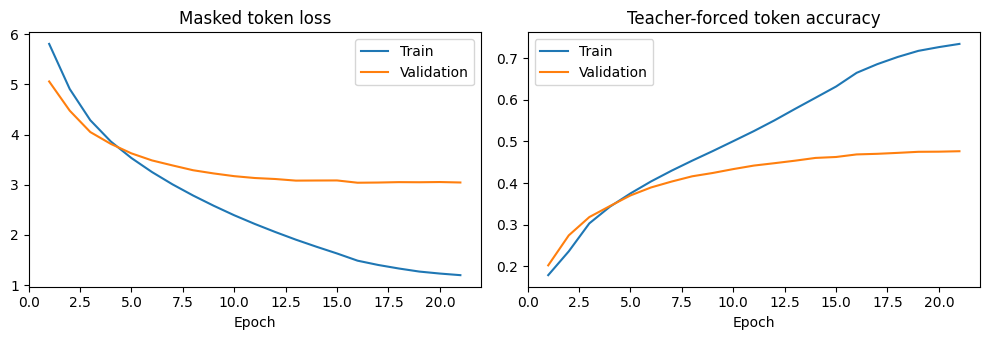

In [14]:
results = translation_model.evaluate(
    [x_test, din_test], y_test, batch_size=BATCH_SIZE, return_dict=True, verbose=0)
print(f"Test teacher-forced loss: {results['loss']:.4f}")
print(f"Test teacher-forced non-padding token accuracy: {results['token_accuracy']:.4f}")
print("This accuracy uses reference prefixes; it is NOT free-running translation accuracy.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for key, ax, title in [("loss", axes[0], "Masked token loss"),
                       ("token_accuracy", axes[1], "Teacher-forced token accuracy")]:
    epochs_run = range(1, len(history.history[key]) + 1)
    ax.plot(epochs_run, history.history[key], label="Train")
    ax.plot(epochs_run, history.history["val_" + key], label="Validation")
    ax.set(title=title, xlabel="Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Inference shares the exact trained embeddings, LSTM and Dense weights.
encoder_model = tf.keras.Model(encoder_input, [state_h, state_c])
step_token = tf.keras.Input(shape=(1,), dtype="int32")
step_h = tf.keras.Input(shape=(LATENT_DIM,))
step_c = tf.keras.Input(shape=(LATENT_DIM,))
step_output, next_h, next_c = decoder_lstm(
    target_embedding(step_token), initial_state=[step_h, step_c])
decoder_model = tf.keras.Model(
    [step_token, step_h, step_c], [word_classifier(step_output), next_h, next_c])

# Verify one inference step matches the training graph's first position.
full = translation_model([x_test[:1], din_test[:1]], training=False).numpy()
h0, c0 = encoder_model(x_test[:1], training=False)
step, _, _ = decoder_model([tf.convert_to_tensor(din_test[:1, :1]), h0, c0], training=False)
np.testing.assert_allclose(full[:, :1], step.numpy(), rtol=1e-4, atol=1e-6)
print("Passed: training and inference use identical next-word probabilities.")

def translate_english(sentences, batch_size=64):
    if not sentences:
        return []
    normalized = [normalize_text(s) for s in sentences]
    sequences = source_tokenizer.texts_to_sequences(normalized)
    if any(len(s) > SOURCE_LEN for s in sequences):
        warnings.warn(f"Inputs longer than {SOURCE_LEN} tokens are truncated.")
    x = pad_sequences(sequences, maxlen=SOURCE_LEN, padding="post", truncating="post")
    translations = []
    for offset in range(0, len(x), batch_size):
        batch = x[offset:offset + batch_size]
        h, c = encoder_model(batch, training=False)
        token = np.full((len(batch), 1), START_ID, dtype="int32")
        finished = np.zeros(len(batch), dtype=bool)
        words = [[] for _ in range(len(batch))]
        for _ in range(TARGET_LEN):
            probs, h, c = decoder_model([tf.convert_to_tensor(token), h, c], training=False)
            scores = probs.numpy()[:, 0, :].copy()
            # PAD and START are not valid words to generate; keep UNK visible.
            scores[:, [0, START_ID]] = -1.0
            predicted = scores.argmax(axis=-1)
            for j, word_id in enumerate(predicted):
                if not finished[j]:
                    if word_id == END_ID:
                        finished[j] = True
                    else:
                        words[j].append(target_tokenizer.index_word.get(int(word_id), "<unk>"))
            token = predicted.astype("int32")[:, None]
            if finished.all():
                break
        translations.extend(" ".join(row) for row in words)
    return translations

Passed: training and inference use identical next-word probabilities.


In [16]:
# Test predictions are generated WITHOUT reference French input.
examples = test_df.head(10).copy()
examples["predicted_french"] = translate_english(examples.english.tolist())
# HTML display wraps columns more clearly than a wide printout.
with pd.option_context("display.max_colwidth", 90):
    display(examples.reset_index(drop=True))

new_sentences = ["How are you?", "The product is good.", "Thank you."]
new_predictions = translate_english(new_sentences)
display(pd.DataFrame({"english": new_sentences, "predicted_french": new_predictions}))

# A separate free-running translation metric, on a disclosed held-out subset.
import sacrebleu
bleu_df = test_df.sample(n=min(200, len(test_df)), random_state=SEED)
hypotheses = translate_english(bleu_df.english.tolist())
bleu = sacrebleu.corpus_bleu(hypotheses, [bleu_df.french.tolist()])
print(f"Free-running BLEU on {len(bleu_df)} normalized test pairs: {bleu.score:.2f}")
print("BLEU settings:", bleu.format())

,english,french,predicted_french
0,may i start eating now,puis je commencer à manger maintenant,puis je utiliser votre manteau
1,don't you want to sit in the front tom,ne veux tu pas t'assoir devant tom,ne vous dites vous pas à la porte
2,he jumped out of bed,il a sauté du lit,il a été expulsé de la maison
3,i really enjoyed that,j'y ai vraiment pris plaisir,j'ai vraiment fait ça
4,it's not supposed to be fun,ce n'est pas censé être amusant,ce n'est pas si ridicule que ça
5,do the police know about this,la police est elle au courant,la prochaine chose à la question
6,i believed in myself,j'ai cru en moi,je me sens en sécurité
7,i used to love swimming,j'adorais nager,j'ai voyagé à travers
8,they don't take care of that dog,ils ne prennent pas soin de ce chien,ils ne sont pas vraiment pour être en sécurité
9,i fell asleep while reading a book,je me suis endormi en lisant un livre,je me suis levé tôt j'ai perdu aujourd'hui


,english,predicted_french
0,How are you?,comment es tu
1,The product is good.,le poisson est vraiment
2,Thank you.,merci


Free-running BLEU on 200 normalized test pairs: 9.50
BLEU settings: BLEU = 9.50 33.1/14.0/6.2/2.8 (BP = 1.000 ratio = 1.091 hyp_len = 1369 ref_len = 1255)


The model achieved 46.79% teacher-forced test token accuracy and a BLEU score of 9.50 on 200 test sentences. Some short phrases were translated correctly, but many translations changed the original meaning. The training and validation results suggest overfitting.